<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Spatial maps of uRNA categories and staining composites under each segmentation method.
> - **Manuscript panels:** Fig. 2C, ED Fig. 2G
> - **Inputs:** `data_with_source_score.zarr` of xenium_hsprostate (rois, rois_proseg, rois_segger)
> - **Outputs:** `spatial_transcripts_*.pdf`, `staining_composite*.pdf`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Quantify cell-like proportions 

# Import modules

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import os

from troutpy_reproducibility.batch_running import *
from troutpy_reproducibility.downstream import *

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
from troutpy import pl
from troutpy import tl
from troutpy import pp


In [3]:
import os
import spatialdata as sd

base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
segmentations = ["rois", "rois_proseg", "rois_segger"]

# 1. Gather all unique subfolder names across both directories
all_subfolders = set()
for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)
    if os.path.exists(root_dir):
        all_subfolders.update([f.name for f in os.scandir(root_dir) if f.is_dir()])

all_subfolders = sorted(list(all_subfolders))
print(all_subfolders)

['atera_hsbreast', 'cosmx_hgsoc', 'cosmx_melanoma', 'cosmx_mousebrain', 'cosmx_msbrain', 'cosmx_pancreas', 'cosmx_stomach', 'data.zarrls', 'merscope_hsbrain', 'merscope_hsuterine', 'xenium_hsfemur', 'xenium_hsheart', 'xenium_hsopsc_5k', 'xenium_hsopsc_v1', 'xenium_hsprostate', 'xenium_hsputamen', 'xenium_hsskin_5k', 'xenium_msbrain_300', 'xenium_msbrain_5k', 'xenium_msbrain_5k_large', 'xenium_mscolon_5k', 'xenium_opsc_5k', 'xenium_opsc_v1', 'xenium_rcc', 'xenium_rcc_oldzarr']


In [4]:


# Dictionary to hold the loaded sdata objects
# Format will be: { 'subfolder_name': { 'rois': sdata_obj, 'rois_proseg': sdata_obj } }
sdata_collection = {}

# 2. Loop through each subfolder and read both segmentation types
#for subfolder in all_subfolders:
#subfolder='xenium_msbrain_5k'  
subfolder='xenium_hsprostate'  
sdata_collection[subfolder] = {}

for seg in segmentations:
    zarr_path = os.path.join(base_dir, seg, subfolder, 'data_processed_full.zarr')
    
    if os.path.exists(zarr_path):
        print(f"Reading: {seg}/{subfolder}")
        try:
            # Read and store the object
            sdata_collection[subfolder][seg] = sd.read_zarr(zarr_path)
        except Exception as e:
            print(f"Failed to read {seg}/{subfolder}: {e}")
            sdata_collection[subfolder][seg] = None
    else:
        print(f"Path missing for {seg}/{subfolder}")
        sdata_collection[subfolder][seg] = None

version mismatch: detected: RasterFormatV02, requested: FormatV04


Reading: rois/xenium_hsprostate


version mismatch: detected: RasterFormatV02, requested: FormatV04


Reading: rois_proseg/xenium_hsprostate


version mismatch: detected: RasterFormatV02, requested: FormatV04


Reading: rois_segger/xenium_hsprostate


## Load functions

In [5]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap
from shapely.geometry import box

import os

import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from adjustText import adjust_text
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.lines import Line2D
from shapely.affinity import affine_transform
from shapely.geometry import box
from spatialdata import SpatialData
from spatialdata.transformations import get_transformation
from troutpy.pl.colors import get_colormap, get_palette


def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "point_source_cellular",
    shapes_key: str | list[str] = "cell_boundaries",  # Updated to accept string or list of strings
    table_key: str = "table",
    structure_table_key: str = "structure_table",
    source_table_key: str = "source_score",
    colormap: str = "30colors",
    continuous_colormap: str = "viridis",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    scatter_size: float = 1.0,
    alpha: float = 1.0,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
    vmin: float | None = None,
    vmax: float | None = None,
    rasterize: bool = True,
    missing_val_sentinel: int | str | float = -1,
) -> tuple[plt.Figure, plt.Axes]:
    """Plot spatial transcripts colored by a grouping variable, overlaid on cell boundaries."""
    
    # Determine the minimal set of columns to pull from the (lazy, dask-backed) transcripts table
    target_col = "point_source" if color_key == "point_source_cellular" else color_key
    required_cols = ["x", "y", gene_key, "overlaps_cell"]

    transcripts_lazy = sdata.points["transcripts"]
    is_direct_column = target_col in transcripts_lazy.columns

    if is_direct_column:
        required_cols.append(target_col)

    # Tables that may provide target_col via an id-column join with the transcripts table
    search_configs = [
        (source_table_key, None),
        (structure_table_key, "structure_id"),
        (table_key, "cell_id"),
    ]

    for t_key, trans_id_col in search_configs:
        if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
            if trans_id_col is not None:
                required_cols.append(trans_id_col)
            break

    required_cols = list(set(required_cols))
    available_cols = [c for c in required_cols if c in transcripts_lazy.columns]
    transcripts_lazy_subset = transcripts_lazy[available_cols]

    if gene_list is not None:
        transcripts_lazy_subset = transcripts_lazy_subset[transcripts_lazy_subset[gene_key].isin(gene_list)]

    trans_ad = transcripts_lazy_subset.compute().copy()

    if color_key not in trans_ad.columns:
        trans_ad[color_key] = np.nan

    if color_key == "point_source_cellular":
        if target_col not in trans_ad.columns:
            trans_ad[target_col] = np.nan

            for t_key, trans_id_col in search_configs:
                if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
                    table_obs = sdata[t_key].obs
                    if trans_id_col is None:
                        table_series = table_obs[target_col]
                        table_series.index = table_series.index.astype(str)
                        trans_ad[target_col] = trans_ad.index.astype(str).map(table_series)
                    else:
                        if "instance_id" in table_obs.columns:
                            map_source = table_obs.set_index("instance_id")[target_col]
                        elif "cell_id" in table_obs.columns:
                            map_source = table_obs.set_index("cell_id")[target_col]
                        else:
                            map_source = table_obs[target_col]

                        map_source.index = map_source.index.astype(str)
                        trans_ad[target_col] = trans_ad[trans_id_col].astype(str).map(map_source)

                    if not trans_ad[target_col].isna().all():
                        break

        is_intra_bool = trans_ad["overlaps_cell"].astype(str).str.lower() == "true"
        trans_ad["point_source_cellular"] = np.where(is_intra_bool, "cellular transcripts", trans_ad[target_col].astype(str))
        trans_ad.loc[trans_ad[target_col].isna(), "point_source_cellular"] = np.nan

    elif is_direct_column is False:
        for t_key, trans_id_col in search_configs:
            if t_key in sdata.tables and color_key in sdata[t_key].obs.columns:
                table_obs = sdata[t_key].obs
                if trans_id_col is None:
                    table_series = table_obs[color_key]
                    table_series.index = table_series.index.astype(str)
                    trans_ad[color_key] = trans_ad.index.astype(str).map(table_series)
                else:
                    if "instance_id" in table_obs.columns:
                        map_source = table_obs.set_index("instance_id")[color_key]
                    elif "cell_id" in table_obs.columns:
                        map_source = table_obs.set_index("cell_id")[color_key]
                    else:
                        map_source = table_obs[color_key]

                    map_source.index = map_source.index.astype(str)
                    trans_ad[color_key] = trans_ad[trans_id_col].astype(str).map(map_source)

                if not trans_ad[color_key].isna().all():
                    break

    trans_ad[color_key] = trans_ad[color_key].replace("nan", np.nan)
    if missing_val_sentinel is not None:
        sentinel_str = str(missing_val_sentinel)
        trans_ad[color_key] = trans_ad[color_key].replace([missing_val_sentinel, sentinel_str], np.nan)

    is_nan_mask = trans_ad[color_key].isna()
    trans_ad[color_key] = trans_ad[color_key].fillna("Unmapped")
    is_bg = trans_ad[color_key] == "Unmapped"
    trans_df = trans_ad.copy()

    # --- MODIFIED: Standardize shapes_key into a list format ---
    if isinstance(shapes_key, str):
        shapes_keys_list = [shapes_key]
    else:
        shapes_keys_list = shapes_key

    # Load and transform all requested shape collections
    gdfs_to_plot = {}
    for skey in shapes_keys_list:
        if skey in sdata:
            cb = sdata[skey]
            df = cb.copy()
            try:
                trans = get_transformation(cb)
                if hasattr(trans, "matrix") and trans.matrix is not None:
                    m = trans.matrix
                    params = [m[0, 0], m[0, 1], m[1, 0], m[1, 1], m[0, 2], m[1, 2]]
                    df["geometry"] = df["geometry"].apply(lambda g: affine_transform(g, params))
            except Exception:
                pass
            gdfs_to_plot[skey] = gpd.GeoDataFrame(df, geometry="geometry")
        else:
            print(f"Warning: Shapes key '{skey}' not found in SpatialData object.")

    # --- MODIFIED: Safe multi-GDF and single-transcript ROI execution ---
    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)  # Restored your exact working box layout
        
        for skey in gdfs_to_plot:
            gdfs_to_plot[skey] = gdfs_to_plot[skey][gdfs_to_plot[skey].geometry.intersects(roi_poly)]
            
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        is_bg = is_bg[mask]
        is_nan_mask = is_nan_mask[mask]

    fg_df = trans_df[~is_bg].copy()
    unmapped_df = trans_df[is_bg & ~is_nan_mask].copy()

    cmap, norm, is_numeric, cats = None, None, False, None

    if not fg_df.empty:
        numeric_check = pd.to_numeric(fg_df[color_key], errors="coerce")
        if not numeric_check.isna().all() and pd.api.types.is_numeric_dtype(numeric_check):
            is_numeric = True
            vals = fg_df[color_key].astype(float)

            try:
                cmap = plt.get_cmap(colormap)
            except ValueError:
                cmap = plt.get_cmap(continuous_colormap)

            plot_vmin = vmin if vmin is not None else vals.min()
            plot_vmax = vmax if vmax is not None else (1.0 if vals.max() <= 1.0 else vals.max())
            norm = Normalize(vmin=plot_vmin, vmax=plot_vmax)
        else:
            is_numeric = False

            if color_key == "point_source_cellular":
                defined_order = ["cellular transcripts", "cell_like_source", "other", "high_density_source"]
                present_cats = [c for c in defined_order if c in fg_df[color_key].unique()]
                extra_cats = [c for c in fg_df[color_key].unique() if c not in defined_order]
                final_order = present_cats + extra_cats
                fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=final_order, ordered=True)
            else:
                fg_df[color_key] = fg_df[color_key].astype("category")

            cats = fg_df[color_key].cat.categories

            if isinstance(colormap, ListedColormap):
                cmap = colormap
            else:
                try:
                    pal = get_palette(colormap, len(cats))
                    cmap = ListedColormap(pal)
                except ValueError:
                    cmap = plt.get_cmap(colormap if colormap in plt.colormaps() else "tab20", len(cats))

    fig, ax = plt.subplots(figsize=figsize)

    # --- MODIFIED: Loop boundaries with clean, solid distinct colors ---
    edge_colors = ["purple","black","yellow","cyan","red",  "green", "magenta", ]
    boundary_handles = []
    
    for idx, (skey, gdf) in enumerate(gdfs_to_plot.items()):
        ec = edge_colors[idx % len(edge_colors)]
        gdf.plot(
            ax=ax, 
            facecolor="none", 
            edgecolor=ec, 
            linewidth=boundary_linewidth, 
            alpha=1.0, 
            linestyle="-",  # Forced strict continuous solid lines 
            zorder=boundary_zorder # Restored original structural zorder stack position
        )
        # Track invisible line proxies for boundary differentiation in the legend
        line, = ax.plot([], [], color=ec, linestyle="-", label=f"Boundary: {skey}")
        boundary_handles.append(line)

    # Restored your exact working spot scatter expressions
    if not unmapped_df.empty:
        ax.scatter(unmapped_df["x"], unmapped_df["y"], c="#A0A0A0", s=scatter_size, edgecolor="none", alpha=alpha, zorder=2, rasterized=rasterize)

    if not fg_df.empty:
        c_vals = fg_df[color_key] if is_numeric else fg_df[color_key].cat.codes
        scatter = ax.scatter(
            fg_df["x"],
            fg_df["y"],
            c=c_vals,
            cmap=cmap,
            norm=norm if is_numeric else None,
            s=scatter_size * 1.5,
            edgecolor="none",
            alpha=1.0,
            zorder=3,
            rasterized=rasterize,
        )
        if is_numeric:
            fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
            if boundary_handles:
                ax.legend(handles=boundary_handles, loc="upper left", bbox_to_anchor=(1.02, 0.5))
        else:
            if len(cats) <= 30:
                for idx, cat in enumerate(cats):
                    ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
                ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")
    else:
        if boundary_handles:
            ax.legend(handles=boundary_handles, loc="upper left", bbox_to_anchor=(1.02, 1))

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax

In [6]:
import numpy as np
import dask.dataframe as dd
import pandas as pd
from spatialdata import SpatialData
from spatialdata.models import PointsModel
from spatialdata.transformations import get_transformation, set_transformation

def assign_transcript_types(sdata: SpatialData, transcripts_key: str = "transcripts") -> SpatialData:
    """Computes 'transcript_type' classification categories and updates the sdata points layer safely."""
    if transcripts_key not in sdata.points:
        raise KeyError(f"'{transcripts_key}' not found in sdata.points")
        
    # 1. Compute lazy transcripts to a local Pandas DataFrame
    transcripts_lazy = sdata.points[transcripts_key]
    trans = transcripts_lazy.compute().copy()

    # 2. Define the conditional categories step-by-step
    is_intra = trans['overlaps_cell'].astype(str).str.lower() == 'true'
    is_high_density = trans['enrichment_class'].astype(str) == 'High Density'
    is_cell_like = trans['extracellular'].astype(str).str.lower() == 'false'

    # Build hierarchy using np.select
    conditions = [
        is_intra,           # 1st priority: Inside a cell
        is_cell_like,       # 2nd priority: Extracellular, but cell-like
        is_high_density,    # 3rd priority: High Density extracellular
    ]

    # --- PREFIXED STRINGS FOR ENFORCED ALPHABETICAL ORDER ---
    choices = ['1_intracellular', '2_cell-like', '4_High Density']
    
    # Apply conditions, default to '4_other' for everything else
    trans['transcript_type'] = np.select(conditions, choices, default='3_other')
    
    # Ensure it's strictly cast as a string type
    trans['transcript_type'] = trans['transcript_type'].astype(str)
    # ---------------------------------------------------------

    # 3. Preserve the original coordinate transformation metadata graph
    try:
        transformations = get_transformation(transcripts_lazy, get_all=True)
    except Exception:
        transformations = None

    # 4. Parse back to a spatial dask-backed dataframe
    trans_dask = dd.from_pandas(trans, npartitions=transcripts_lazy.npartitions)
    parsed_points = PointsModel.parse(trans_dask, coordinates={'x': 'x', 'y': 'y'})

    # 5. Re-apply coordinate alignments back to the updated element
    if transformations:
        for target_space, transform in transformations.items():
            set_transformation(parsed_points, transform, to_coordinate_system=target_space)

    # Overwrite the layer safely inside the object
    sdata.points[transcripts_key] = parsed_points
    
    return sdata


import numpy as np
import dask.dataframe as dd
import pandas as pd
from spatialdata import SpatialData
from spatialdata.models import PointsModel
from spatialdata.transformations import get_transformation, set_transformation

def assign_transcript_cell_like_types(sdata: SpatialData, transcripts_key: str = "transcripts") -> SpatialData:
    """Computes 'cell_like_type' classification categories and updates the sdata points layer safely."""
    if transcripts_key not in sdata.points:
        raise KeyError(f"'{transcripts_key}' not found in sdata.points")
        
    # 1. Compute lazy transcripts to a local Pandas DataFrame
    transcripts_lazy = sdata.points[transcripts_key]
    trans = transcripts_lazy.compute().copy()

    # 2. Define the conditional categories step-by-step
    is_intra = trans['overlaps_cell'].astype(str).str.lower() == 'true'
    is_cell_like = trans['extracellular'].astype(str).str.lower() == 'false'

    # Build hierarchy using np.select
    conditions = [
        is_intra,           # 1st priority: Inside a cell
        is_cell_like,       # 2nd priority: Extracellular, but cell-like
    ]

    # --- PREFIXED STRINGS FOR ENFORCED ALPHABETICAL ORDER ---
    choices = ['1_intracellular', '2_cell-like']
    
    # Apply conditions, default to '3_non-cell-like' for everything else
    trans['cell_like_type'] = np.select(conditions, choices, default='3_non-cell-like')
    
    # Ensure it's strictly cast as a string type
    trans['cell_like_type'] = trans['cell_like_type'].astype(str)
    # ---------------------------------------------------------

    # 3. Preserve the original coordinate transformation metadata graph
    try:
        transformations = get_transformation(transcripts_lazy, get_all=True)
    except Exception:
        transformations = None

    # 4. Parse back to a spatial dask-backed dataframe
    trans_dask = dd.from_pandas(trans, npartitions=transcripts_lazy.npartitions)
    parsed_points = PointsModel.parse(trans_dask, coordinates={'x': 'x', 'y': 'y'})

    # 5. Re-apply coordinate alignments back to the updated element
    if transformations:
        for target_space, transform in transformations.items():
            set_transformation(parsed_points, transform, to_coordinate_system=target_space)

    # Overwrite the layer safely inside the object
    sdata.points[transcripts_key] = parsed_points
    
    return sdata

import numpy as np
import dask.dataframe as dd
from spatialdata import SpatialData
from spatialdata.models import PointsModel
from spatialdata.transformations import get_transformation, set_transformation
import numpy as np
import dask.dataframe as dd
from spatialdata import SpatialData
from spatialdata.models import PointsModel
from spatialdata.transformations import get_transformation, set_transformation

import numpy as np
import dask.dataframe as dd
from spatialdata import SpatialData
from spatialdata.models import PointsModel
from spatialdata.transformations import get_transformation, set_transformation

def assign_transcript_agg_types(sdata: SpatialData, transcripts_key: str = "transcripts") -> SpatialData:
    """Computes 'agg_type' classification categories and updates the sdata points layer safely."""
    if transcripts_key not in sdata.points:
        raise KeyError(f"'{transcripts_key}' not found in sdata.points")
        
    # 1. Compute lazy transcripts to a local Pandas DataFrame
    transcripts_lazy = sdata.points[transcripts_key]
    trans = transcripts_lazy.compute().copy()

    # 2. Extract base logical flags using your updated definitions
    is_intra = trans['overlaps_cell'].astype(str).str.lower() == 'true'
    is_high_density = trans['enrichment_class'].astype(str) == 'High Density'
    is_cell_like = (trans['overlaps_cell'].astype(str).str.lower() == 'false') & (trans['extracellular'].astype(str).str.lower() == 'false')
    is_extracellular = ~is_intra

    # Build the 5 mutually exclusive combinations based on priority rules
    conditions = [
        is_intra,                                            # 1. Intracellular (Highest priority)
        is_high_density & is_cell_like & is_extracellular,   # 2. High-Density & Cell-Like (Double Positive)
        is_high_density & (~is_cell_like) & is_extracellular, # 3. High-Density Only
        (~is_high_density) & is_cell_like & is_extracellular  # 4. Cell-Like Only
    ]

    # --- PREFIXED STRINGS FOR ENFORCED ALPHABETICAL ORDER ---
    choices = [
        '1_intracellular',
        '2_hd_cell_like', 
        '3_hd_only', 
        '4_cell_like_only'
    ]
    
    # Apply conditions, defaulting to '5_other' for the double-negative background pool
    trans['agg_type'] = np.select(conditions, choices, default='5_other')
    
    # Ensure it's strictly cast as a string type
    trans['agg_type'] = trans['agg_type'].astype(str)
    # ---------------------------------------------------------

    # 3. Preserve the original coordinate transformation metadata graph
    try:
        transformations = get_transformation(transcripts_lazy, get_all=True)
    except Exception:
        transformations = None

    # 4. Parse back to a spatial dask-backed dataframe
    trans_dask = dd.from_pandas(trans, npartitions=transcripts_lazy.npartitions)
    parsed_points = PointsModel.parse(trans_dask, coordinates={'x': 'x', 'y': 'y'})

    # 5. Re-apply coordinate alignments back to the updated element
    if transformations:
        for target_space, transform in transformations.items():
            set_transformation(parsed_points, transform, to_coordinate_system=target_space)

    # Overwrite the layer safely inside the object
    sdata.points[transcripts_key] = parsed_points
    
    return sdata

In [7]:
def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "point_source_cellular",
    shapes_key: str | list[str] = "cell_boundaries",  
    table_key: str = "table",
    structure_table_key: str = "structure_table",
    source_table_key: str = "source_score",
    colormap: str | list[str] | ListedColormap = "30colors",  
    continuous_colormap: str = "viridis",
    boundary_colors: list[str] | None = None,            # NEW: Custom hex list for boundary lines
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    scatter_size: float = 1.0,
    alpha: float = 1.0,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
    vmin: float | None = None,
    vmax: float | None = None,
    rasterize: bool = True,
    missing_val_sentinel: int | str | float = -1,
) -> tuple[plt.Figure, plt.Axes]:
    """Plot spatial transcripts colored by a grouping variable, overlaid on cell boundaries."""
    
    # Determine the minimal set of columns to pull from the (lazy, dask-backed) transcripts table
    target_col = "point_source" if color_key == "point_source_cellular" else color_key
    required_cols = ["x", "y", gene_key, "overlaps_cell"]

    transcripts_lazy = sdata.points["transcripts"]
    is_direct_column = target_col in transcripts_lazy.columns

    if is_direct_column:
        required_cols.append(target_col)

    # Tables that may provide target_col via an id-column join with the transcripts table
    search_configs = [
        (source_table_key, None),
        (structure_table_key, "structure_id"),
        (table_key, "cell_id"),
    ]

    for t_key, trans_id_col in search_configs:
        if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
            if trans_id_col is not None:
                required_cols.append(trans_id_col)
            break

    required_cols = list(set(required_cols))
    available_cols = [c for c in required_cols if c in transcripts_lazy.columns]
    transcripts_lazy_subset = transcripts_lazy[available_cols]

    if gene_list is not None:
        transcripts_lazy_subset = transcripts_lazy_subset[transcripts_lazy_subset[gene_key].isin(gene_list)]

    trans_ad = transcripts_lazy_subset.compute().copy()

    if color_key not in trans_ad.columns:
        trans_ad[color_key] = np.nan

    if color_key == "point_source_cellular":
        if target_col not in trans_ad.columns:
            trans_ad[target_col] = np.nan

            for t_key, trans_id_col in search_configs:
                if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
                    table_obs = sdata[t_key].obs
                    if trans_id_col is None:
                        table_series = table_obs[target_col]
                        table_series.index = table_series.index.astype(str)
                        trans_ad[target_col] = trans_ad.index.astype(str).map(table_series)
                    else:
                        if "instance_id" in table_obs.columns:
                            map_source = table_obs.set_index("instance_id")[target_col]
                        elif "cell_id" in table_obs.columns:
                            map_source = table_obs.set_index("cell_id")[target_col]
                        else:
                            map_source = table_obs[target_col]

                        map_source.index = map_source.index.astype(str)
                        trans_ad[target_col] = trans_ad[trans_id_col].astype(str).map(map_source)

                    if not trans_ad[target_col].isna().all():
                        break

        is_intra_bool = trans_ad["overlaps_cell"].astype(str).str.lower() == "true"
        trans_ad["point_source_cellular"] = np.where(is_intra_bool, "cellular transcripts", trans_ad[target_col].astype(str))
        trans_ad.loc[trans_ad[target_col].isna(), "point_source_cellular"] = np.nan

    elif is_direct_column is False:
        for t_key, trans_id_col in search_configs:
            if t_key in sdata.tables and color_key in sdata[t_key].obs.columns:
                table_obs = sdata[t_key].obs
                if trans_id_col is None:
                    table_series = table_obs[color_key]
                    table_series.index = table_series.index.astype(str)
                    trans_ad[color_key] = trans_ad.index.astype(str).map(table_series)
                else:
                    if "instance_id" in table_obs.columns:
                        map_source = table_obs.set_index("instance_id")[color_key]
                    elif "cell_id" in table_obs.columns:
                        map_source = table_obs.set_index("cell_id")[color_key]
                    else:
                        map_source = table_obs[color_key]

                    map_source.index = map_source.index.astype(str)
                    trans_ad[color_key] = trans_ad[trans_id_col].astype(str).map(map_source)

                if not trans_ad[color_key].isna().all():
                    break

    trans_ad[color_key] = trans_ad[color_key].replace("nan", np.nan)
    if missing_val_sentinel is not None:
        sentinel_str = str(missing_val_sentinel)
        trans_ad[color_key] = trans_ad[color_key].replace([missing_val_sentinel, sentinel_str], np.nan)

    is_nan_mask = trans_ad[color_key].isna()
    trans_ad[color_key] = trans_ad[color_key].fillna("Unmapped")
    is_bg = trans_ad[color_key] == "Unmapped"
    trans_df = trans_ad.copy()

    if isinstance(shapes_key, str):
        shapes_keys_list = [shapes_key]
    else:
        shapes_keys_list = shapes_key

    # Load and transform all requested shape collections
    gdfs_to_plot = {}
    for skey in shapes_keys_list:
        if skey in sdata:
            cb = sdata[skey]
            df = cb.copy()
            try:
                trans = get_transformation(cb)
                if hasattr(trans, "matrix") and trans.matrix is not None:
                    m = trans.matrix
                    params = [m[0, 0], m[0, 1], m[1, 0], m[1, 1], m[0, 2], m[1, 2]]
                    df["geometry"] = df["geometry"].apply(lambda g: affine_transform(g, params))
            except Exception:
                pass
            gdfs_to_plot[skey] = gpd.GeoDataFrame(df, geometry="geometry")
        else:
            print(f"Warning: Shapes key '{skey}' not found in SpatialData object.")

    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)  
        
        for skey in gdfs_to_plot:
            gdfs_to_plot[skey] = gdfs_to_plot[skey][gdfs_to_plot[skey].geometry.intersects(roi_poly)]
            
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        is_bg = is_bg[mask]
        is_nan_mask = is_nan_mask[mask]

    fg_df = trans_df[~is_bg].copy()
    unmapped_df = trans_df[is_bg & ~is_nan_mask].copy()

    cmap, norm, is_numeric, cats = None, None, False, None

    if not fg_df.empty:
        numeric_check = pd.to_numeric(fg_df[color_key], errors="coerce")
        if not numeric_check.isna().all() and pd.api.types.is_numeric_dtype(numeric_check):
            is_numeric = True
            vals = fg_df[color_key].astype(float)

            try:
                cmap = plt.get_cmap(colormap)
            except (ValueError, TypeError):
                cmap = plt.get_cmap(continuous_colormap)

            plot_vmin = vmin if vmin is not None else vals.min()
            plot_vmax = vmax if vmax is not None else (1.0 if vals.max() <= 1.0 else vals.max())
            norm = Normalize(vmin=plot_vmin, vmax=plot_vmax)
        else:
            is_numeric = False

            if color_key == "point_source_cellular":
                defined_order = ["cellular transcripts", "cell_like_source", "other", "high_density_source"]
                present_cats = [c for c in defined_order if c in fg_df[color_key].unique()]
                extra_cats = [c for c in fg_df[color_key].unique() if c not in defined_order]
                final_order = present_cats + extra_cats
                fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=final_order, ordered=True)
            else:
                fg_df[color_key] = fg_df[color_key].astype("category")

            cats = fg_df[color_key].cat.categories

            if isinstance(colormap, (list, np.ndarray, pd.Series)):
                palette_colors = [colormap[i % len(colormap)] for i in range(len(cats))]
                cmap = ListedColormap(palette_colors)
            elif isinstance(colormap, ListedColormap):
                cmap = colormap
            else:
                try:
                    pal = get_palette(colormap, len(cats))
                    cmap = ListedColormap(pal)
                except ValueError:
                    cmap = plt.get_cmap(colormap if colormap in plt.colormaps() else "tab20", len(cats))

    fig, ax = plt.subplots(figsize=figsize)

    # --- MODIFIED SECTION: Set dynamic boundary colors from parameter ---
    if boundary_colors is None:
        edge_colors = ["purple", "black", "yellow", "cyan", "red", "green", "magenta"]
    else:
        edge_colors = boundary_colors
    # ---------------------------------------------------------------------

    boundary_handles = []
    
    for idx, (skey, gdf) in enumerate(gdfs_to_plot.items()):
        ec = edge_colors[idx % len(edge_colors)]
        gdf.plot(
            ax=ax, 
            facecolor="none", 
            edgecolor=ec, 
            linewidth=boundary_linewidth, 
            alpha=1.0, 
            linestyle="-",  
            zorder=boundary_zorder 
        )
        line, = ax.plot([], [], color=ec, linestyle="-", label=f"Boundary: {skey}")
        boundary_handles.append(line)

    if not unmapped_df.empty:
        ax.scatter(unmapped_df["x"], unmapped_df["y"], c="#A0A0A0", s=scatter_size, edgecolor="none", alpha=alpha, zorder=2, rasterized=rasterize)

    if not fg_df.empty:
        c_vals = fg_df[color_key] if is_numeric else fg_df[color_key].cat.codes
        scatter = ax.scatter(
            fg_df["x"],
            fg_df["y"],
            c=c_vals,
            cmap=cmap,
            norm=norm if is_numeric else None,
            s=scatter_size * 1.5,
            edgecolor="none",
            alpha=1.0,
            zorder=3,
            rasterized=rasterize,
        )
        if is_numeric:
            fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
            if boundary_handles:
                ax.legend(handles=boundary_handles, loc="upper left", bbox_to_anchor=(1.02, 0.5))
        else:
            if len(cats) <= 30:
                for idx, cat in enumerate(cats):
                    ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
                ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")
    else:
        if boundary_handles:
            ax.legend(handles=boundary_handles, loc="upper left", bbox_to_anchor=(1.02, 1))

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax

## Assigned

In [8]:
import matplotlib.pyplot as plt

# 1. Select the dataset
dataset_name = "xenium_hsprostate"
saving_path='/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_hsprostate'
os.makedirs(saving_path, exist_ok=True)

# 2. Pull out all sdata objects safely
sdata_rois = sdata_collection[dataset_name]["rois"]
sdata_proseg = sdata_collection[dataset_name]["rois_proseg"]
sdata_segger = sdata_collection[dataset_name]["rois_segger"]

# 3. FIX: Create an actual copy so we don't alter the original dictionary cache
combined_sdata = sdata_rois

# 4. Inject the proseg and segger boundaries into the copied object under new keys
combined_sdata.shapes["cell_boundaries_proseg"] = sdata_proseg.shapes["cell_boundaries"]
combined_sdata.shapes["cell_boundaries_segger"] = sdata_segger.shapes["cell_boundaries"]


In [9]:
combined_sdata=assign_transcript_cell_like_types(combined_sdata)
combined_sdata=assign_transcript_agg_types(combined_sdata)
# Process the data
#combined_sdata = assign_transcript_types(combined_sdata)

INFO     Column `z` in `data` will be ignored since the data is 2D.                                                


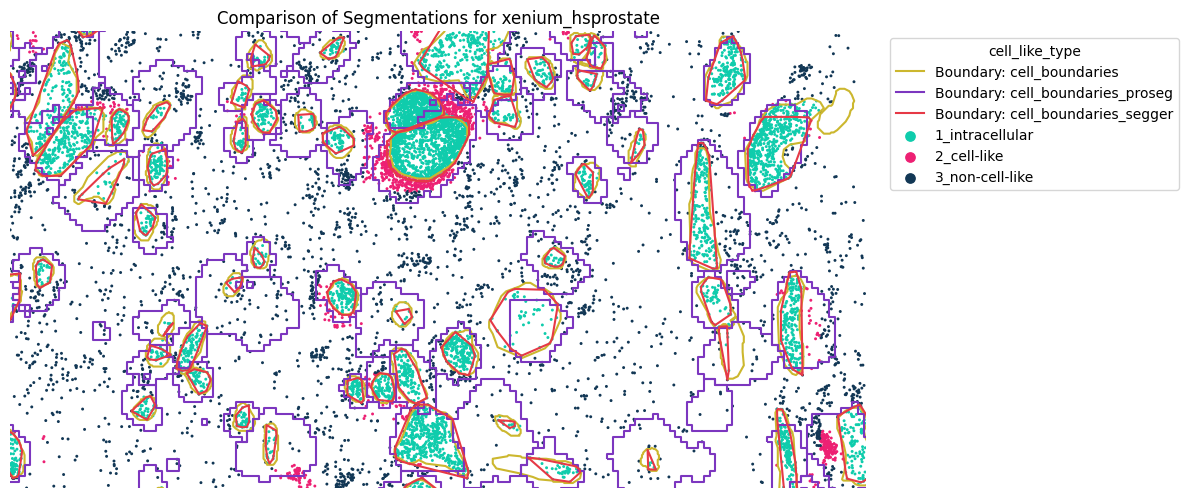

In [10]:
import os
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define your ROI and color key variables cleanly
roi_coords = (850, 1000, 2700, 2780)
chosen_color_key = "cell_like_type"

# 5. Plot them together!
fig, ax = spatial_transcripts(sdata=combined_sdata,shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], 
    color_key=chosen_color_key,use_roi=True, 
    boundary_colors=['#ccb72e', '#7c36bf', '#e63946'],boundary_linewidth=1.5, 
    figsize=(12, 12),   
    roi=roi_coords,
    scatter_size=3.0,
    rasterize=True,                                           # <-- Enforces pixel rasterization for the scatter layer
    title=f"Comparison of Segmentations for {dataset_name}"
)

# Convert ROI tuple into a clean string layout for the filename
roi_str = "_".join(map(str, roi_coords))

# Generate a clean, descriptive filename
output_filename = f"spatial_transcripts_{dataset_name}_{chosen_color_key}_roi_{roi_str}.pdf"

# Save the figure with a tight bounding box
fig.savefig(
    os.path.join(saving_path, output_filename),
    format='pdf',
    bbox_inches='tight',
    dpi=300                                                   # Sets resolution for the rasterized transcript points
)

plt.show()

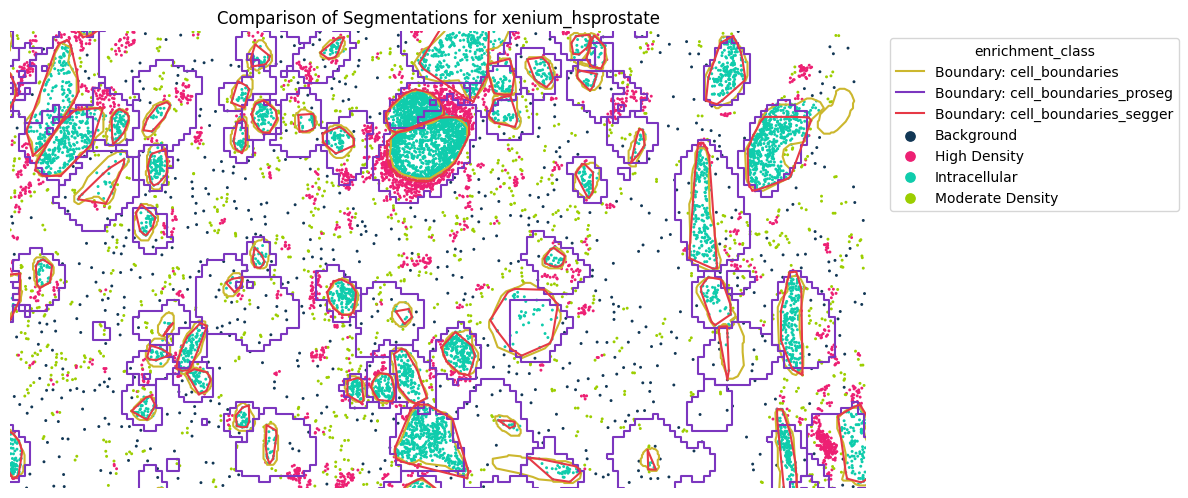

In [11]:
import os
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define your ROI and color key variables cleanly
roi_coords = (850, 1000, 2700, 2780)
chosen_color_key = "enrichment_class"
my_category_colors = ["#123755", "#ED2073", "#0FCCAC", "#9CCE00", "#FC911D"]

# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], 
    color_key=chosen_color_key,                             
    colormap=my_category_colors,                              
    use_roi=True, 
    boundary_colors=['#ccb72e', '#7c36bf', '#e63946'],
    boundary_linewidth=1.5, 
    figsize=(12, 12),                                         
    roi=roi_coords, 
    scatter_size=3.0,                                         
    rasterize=True,                                           # <-- Enforces pixel rasterization for the scatter layer
    title=f"Comparison of Segmentations for {dataset_name}"
)

# Convert ROI tuple into a clean string layout for the filename
roi_str = "_".join(map(str, roi_coords))

# Generate a clean, descriptive filename
output_filename = f"spatial_transcripts_{dataset_name}_{chosen_color_key}_roi_{roi_str}.pdf"

# Save the figure with a tight bounding box
fig.savefig(
    os.path.join(saving_path, output_filename),
    format='pdf',
    bbox_inches='tight',
    dpi=300                                                   # Sets resolution for the rasterized transcript points
)

plt.show()

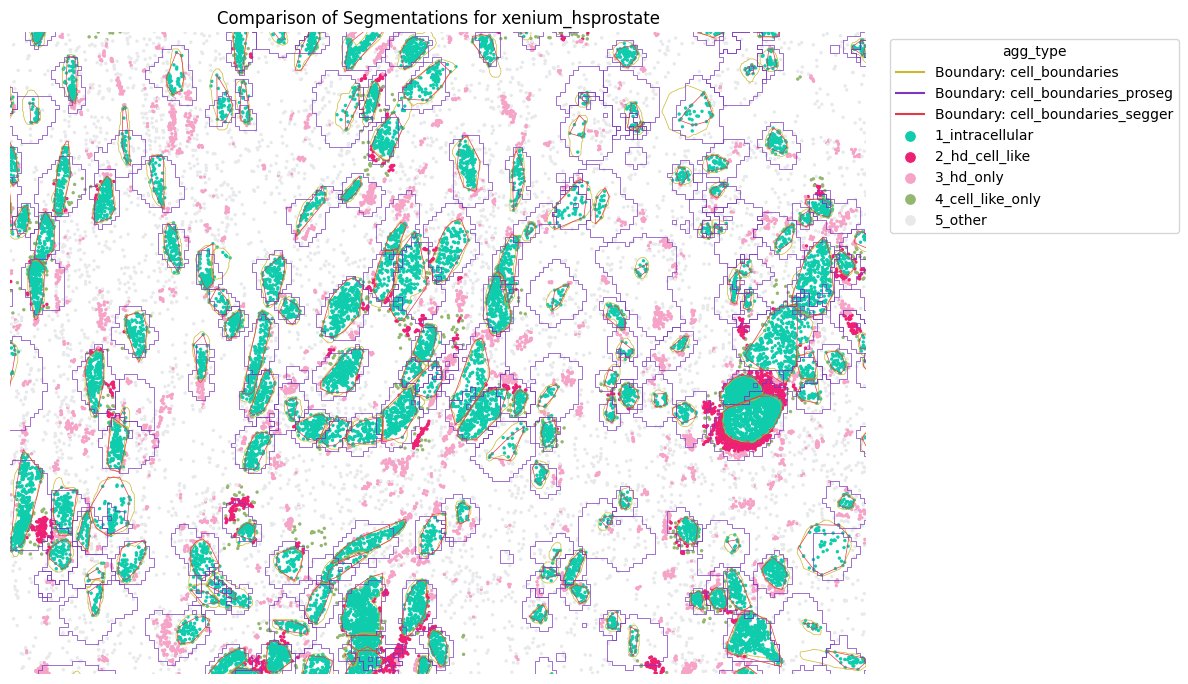

In [12]:
import os
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define your ROI and color key variables cleanly
roi_coords = (750, 950, 2700, 2850)
chosen_color_key = "agg_type"
my_category_colors = ["#0FCCAC", "#ED2073", "#f5a3c7", "#93b76e", "#e8e9eb"]

# 5. Plot them together!
fig, ax = spatial_transcripts(sdata=combined_sdata,shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], 
    color_key=chosen_color_key,use_roi=True, 
    boundary_colors=['#ccb72e', '#7c36bf', '#e63946'],boundary_linewidth=0.5, 
    figsize=(12, 12),   
    roi=roi_coords,
    scatter_size=4.0, colormap=my_category_colors,  
    rasterize=True,                                           # <-- Enforces pixel rasterization for the scatter layer
    title=f"Comparison of Segmentations for {dataset_name}"
)

# Convert ROI tuple into a clean string layout for the filename
roi_str = "_".join(map(str, roi_coords))

# Generate a clean, descriptive filename
output_filename = f"spatial_transcripts_{dataset_name}_{chosen_color_key}_roi_{roi_str}.pdf"

# Save the figure with a tight bounding box
fig.savefig(
    os.path.join(saving_path, output_filename),
    format='pdf',
    bbox_inches='tight',
    dpi=300                                                   # Sets resolution for the rasterized transcript points
)

plt.show()

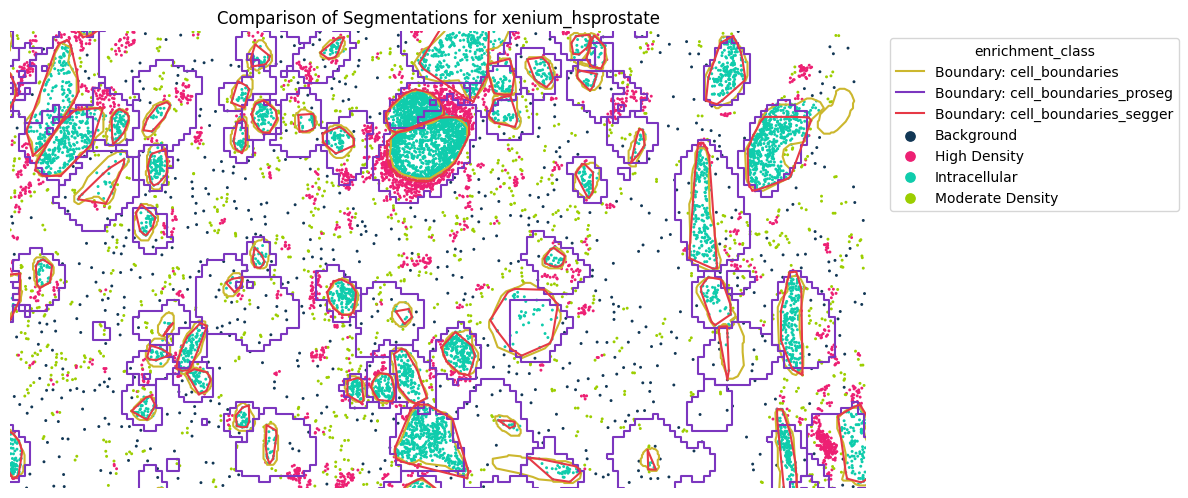

In [13]:
import os
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define your ROI and color key variables cleanly
roi_coords = (850, 1000, 2700, 2780)
chosen_color_key = "enrichment_class"
my_category_colors = ["#123755", "#ED2073", "#0FCCAC", "#9CCE00", "#FC911D"]

# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], 
    color_key=chosen_color_key,                             
    colormap=my_category_colors,                              
    use_roi=True, 
    boundary_colors=['#ccb72e', '#7c36bf', '#e63946'],
    boundary_linewidth=1.5, 
    figsize=(12, 12),                                         
    roi=roi_coords, 
    scatter_size=3.0,                                         
    rasterize=True,                                           # <-- Enforces pixel rasterization for the scatter layer
    title=f"Comparison of Segmentations for {dataset_name}"
)

# Convert ROI tuple into a clean string layout for the filename
roi_str = "_".join(map(str, roi_coords))

# Generate a clean, descriptive filename
output_filename = f"spatial_transcripts_{dataset_name}_{chosen_color_key}_roi_{roi_str}.pdf"

# Save the figure with a tight bounding box
fig.savefig(
    os.path.join(saving_path, output_filename),
    format='pdf',
    bbox_inches='tight',
    dpi=300                                                   # Sets resolution for the rasterized transcript points
)

plt.show()

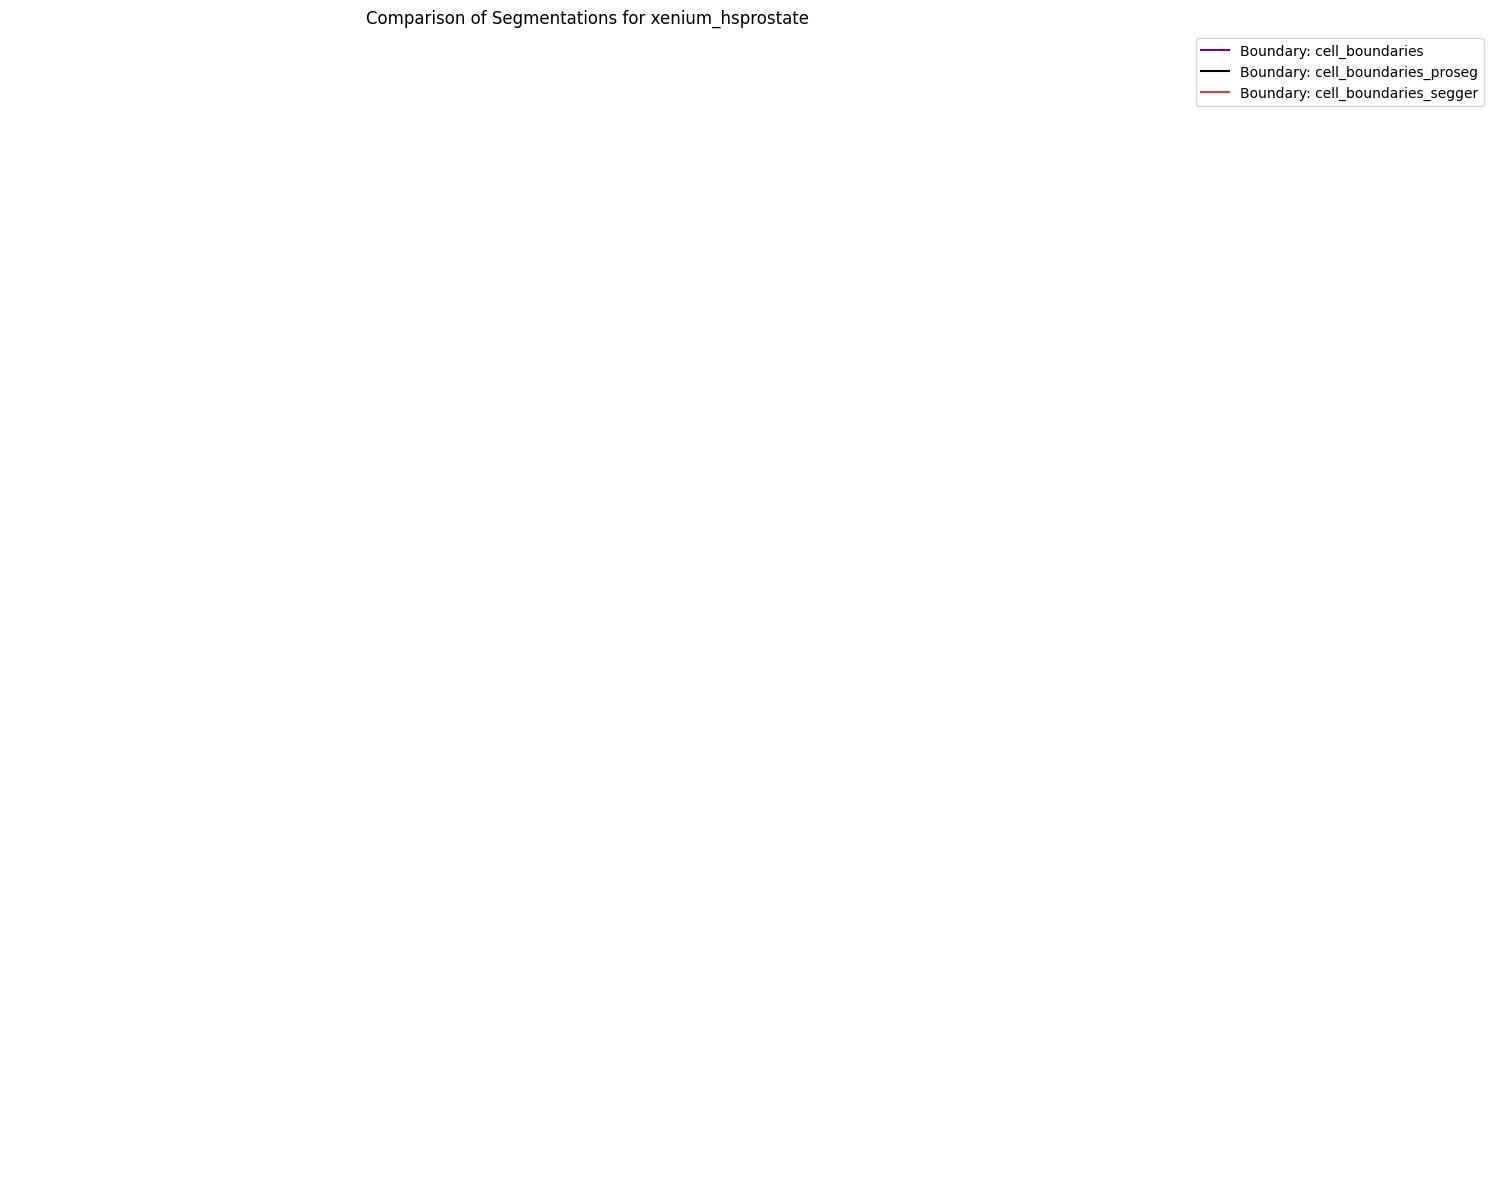

In [14]:

# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], # All three keys passed cleanly as a list
    boundary_colors=['purple', 'black', '#e63946'],
    color_key="cell_like_type",#color_key="point_source_cellular",
    use_roi=True,
    boundary_linewidth=1, figsize=(15,15),   # Solid, crisp outlines
    roi=(3000, 3500, 2000, 2500),scatter_size=0.6,# Your bounding box coordinates
    
    title=f"Comparison of Segmentations for {dataset_name}"
)

plt.show()

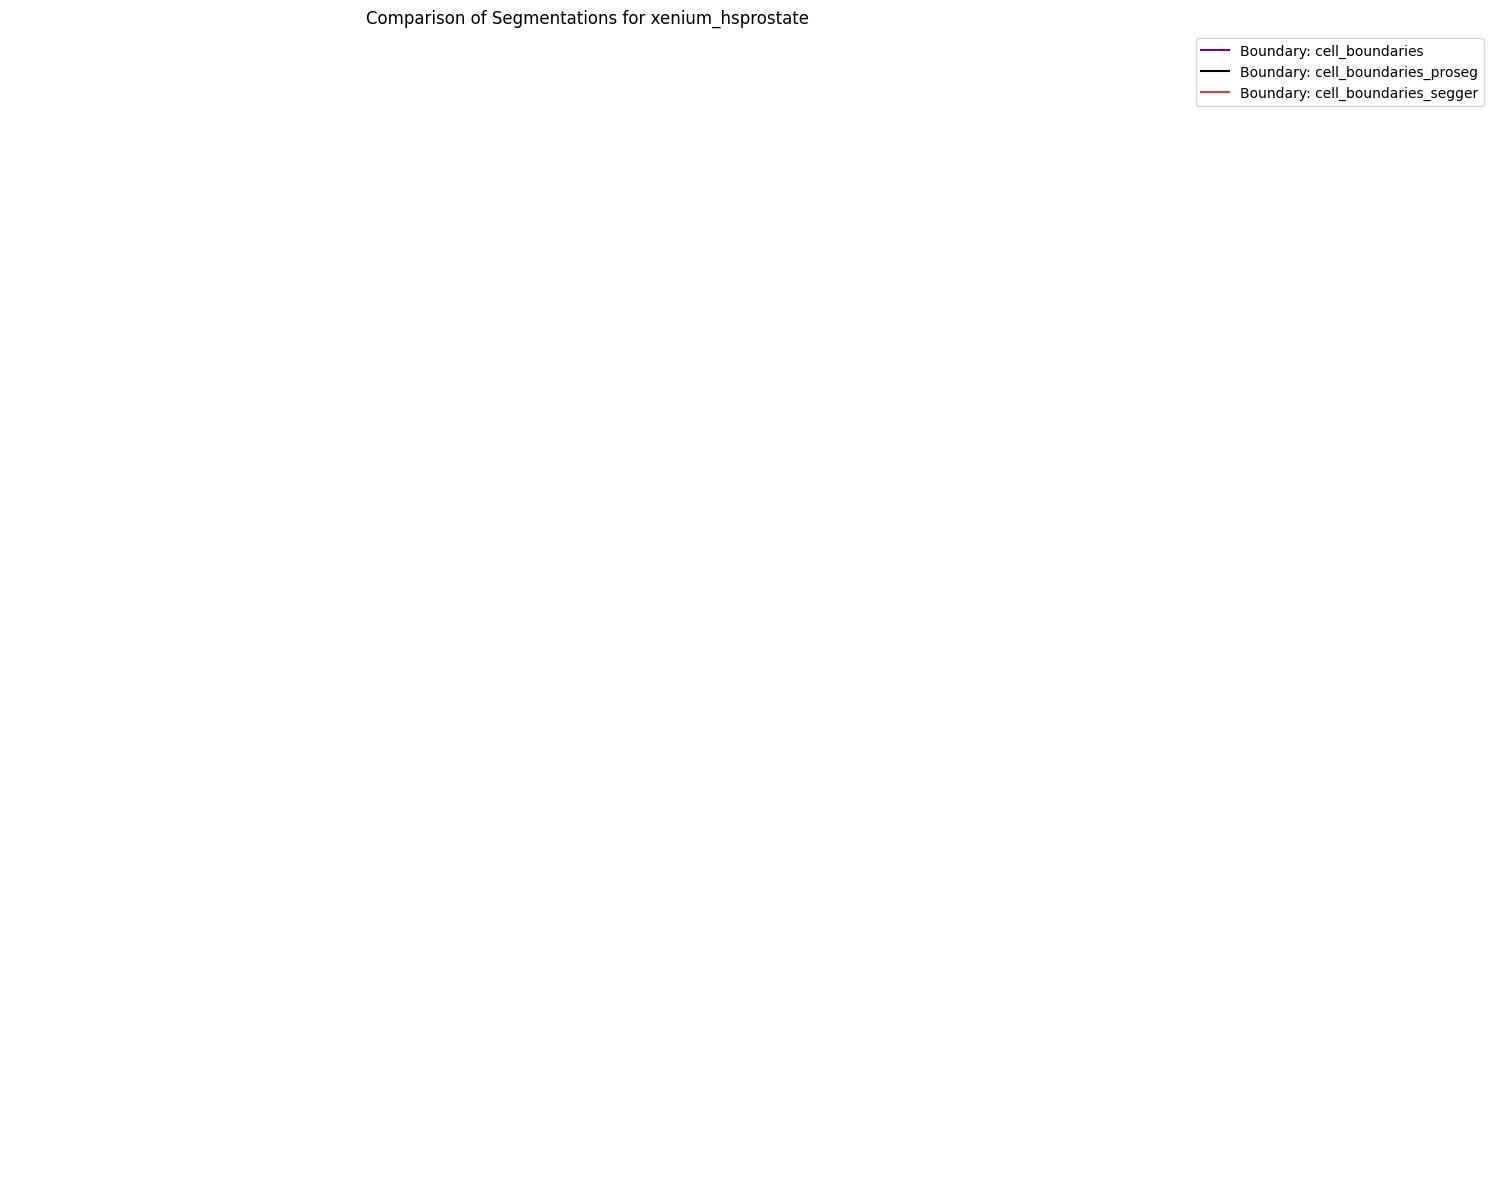

In [15]:

# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], # All three keys passed cleanly as a list
    boundary_colors=['purple', 'black', '#e63946'],
    color_key="transcript_type",#color_key="point_source_cellular",
    use_roi=True,
    boundary_linewidth=2, figsize=(15,15),   # Solid, crisp outlines
    roi=(5100, 5400, 1600, 1900),scatter_size=1.0,# Your bounding box coordinates
    
    title=f"Comparison of Segmentations for {dataset_name}"
)

plt.show()

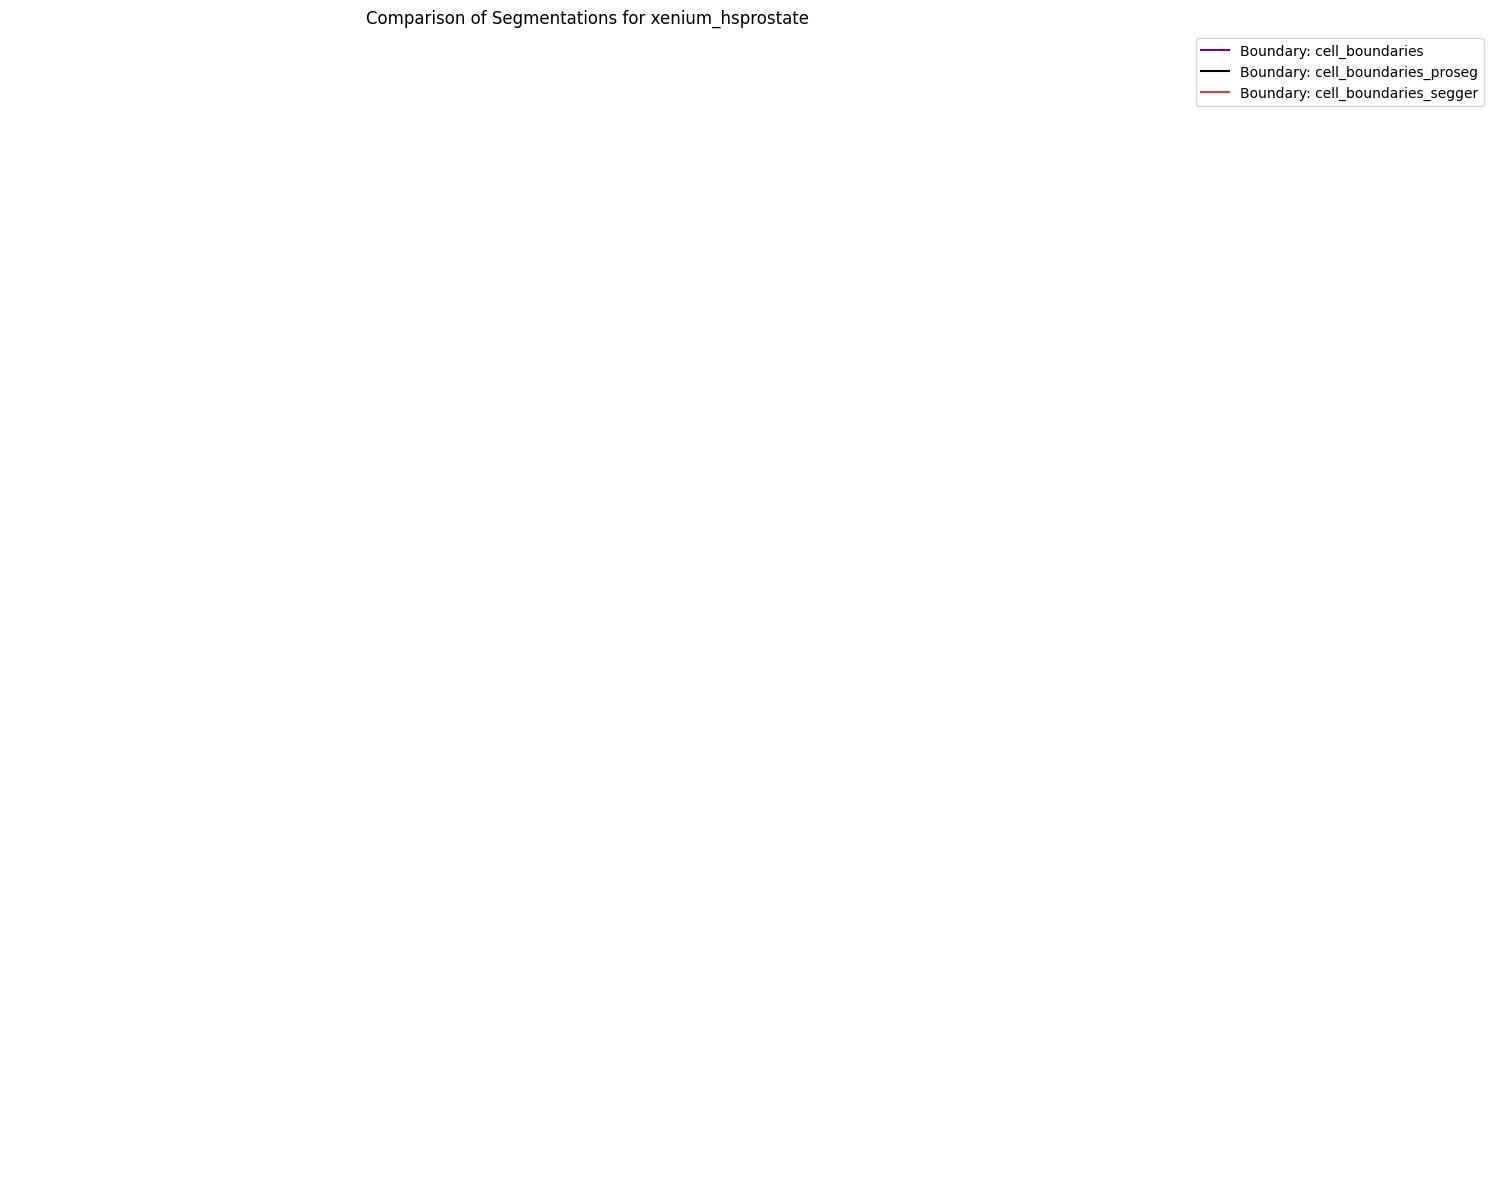

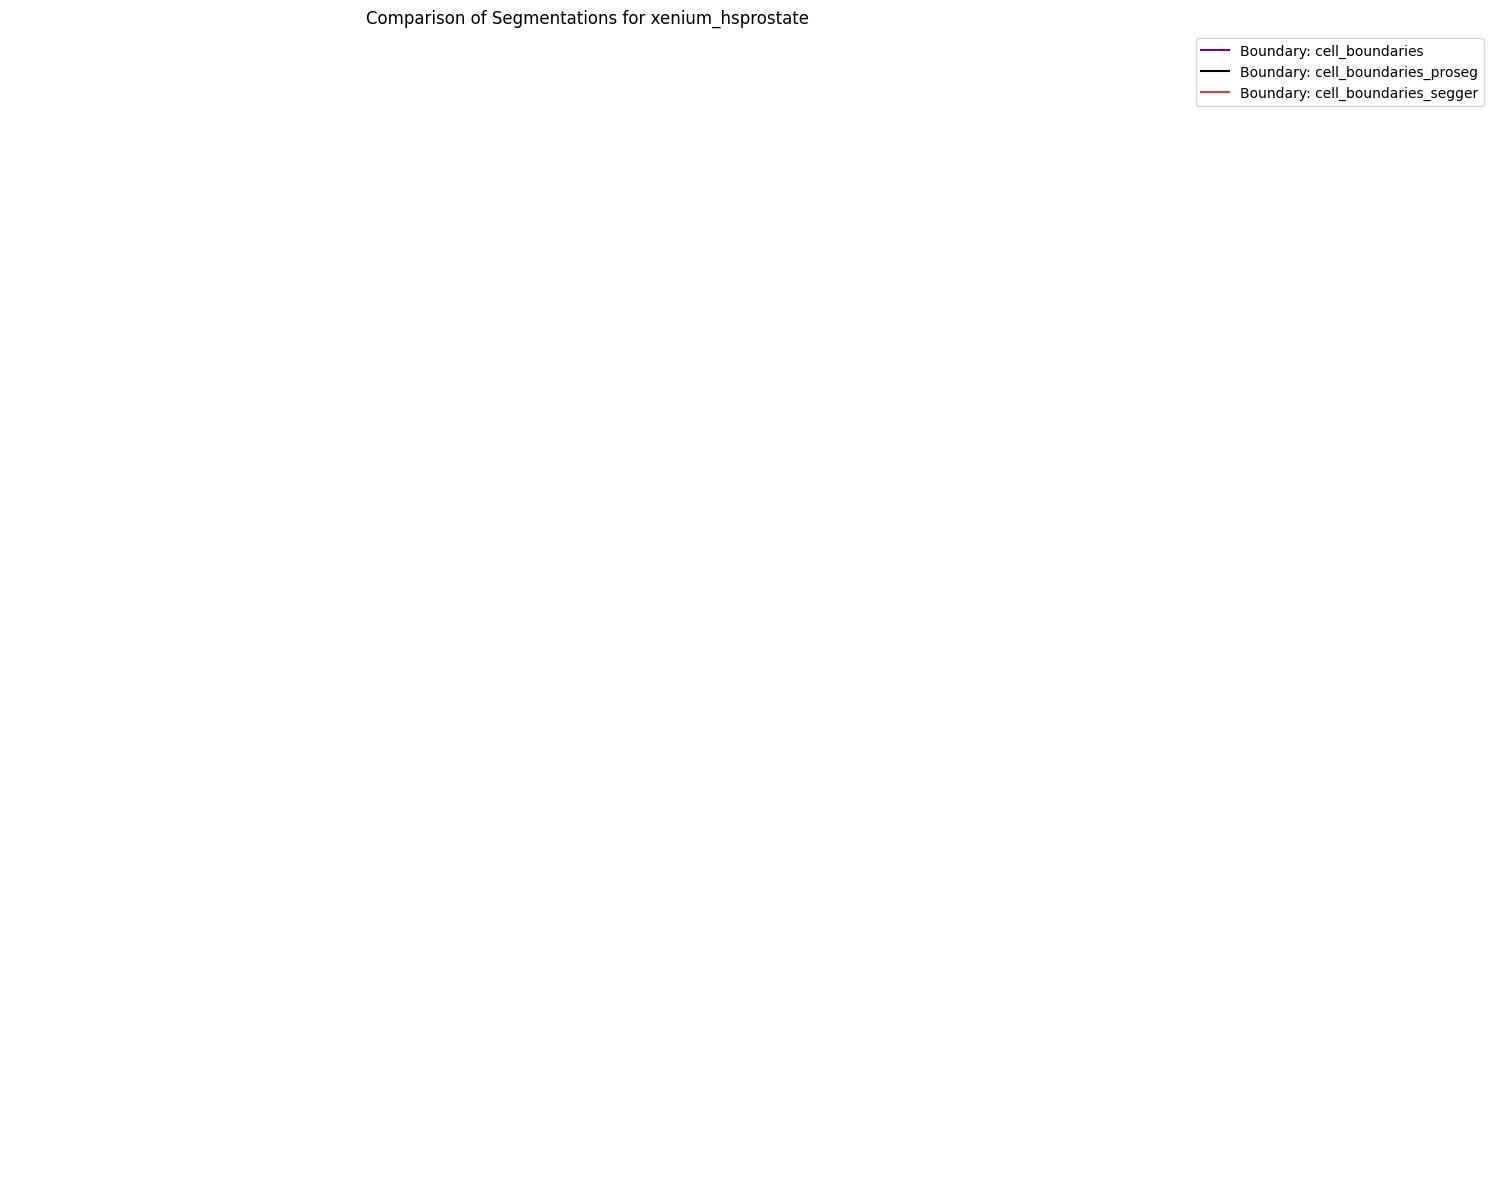

In [16]:
# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], # All three keys passed cleanly as a list
    boundary_colors=['purple', 'black', '#e63946'],
    color_key="enrichment_class",#color_key="point_source_cellular",
    use_roi=True,
    boundary_linewidth=3, figsize=(15,15),   # Solid, crisp outlines
    roi=(5400, 5600, 1900, 2100),scatter_size=0.5,# Your bounding box coordinates
    
    title=f"Comparison of Segmentations for {dataset_name}"
)

plt.show()

# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], # All three keys passed cleanly as a list
    boundary_colors=['purple', 'black', '#e63946'],
    color_key="enrichment_class",#color_key="point_source_cellular",
    use_roi=True,
    boundary_linewidth=3, figsize=(15,15),   # Solid, crisp outlines
    roi=(5600, 5800, 1700, 1900),scatter_size=0.5,# Your bounding box coordinates
    
    title=f"Comparison of Segmentations for {dataset_name}"
)

plt.show()

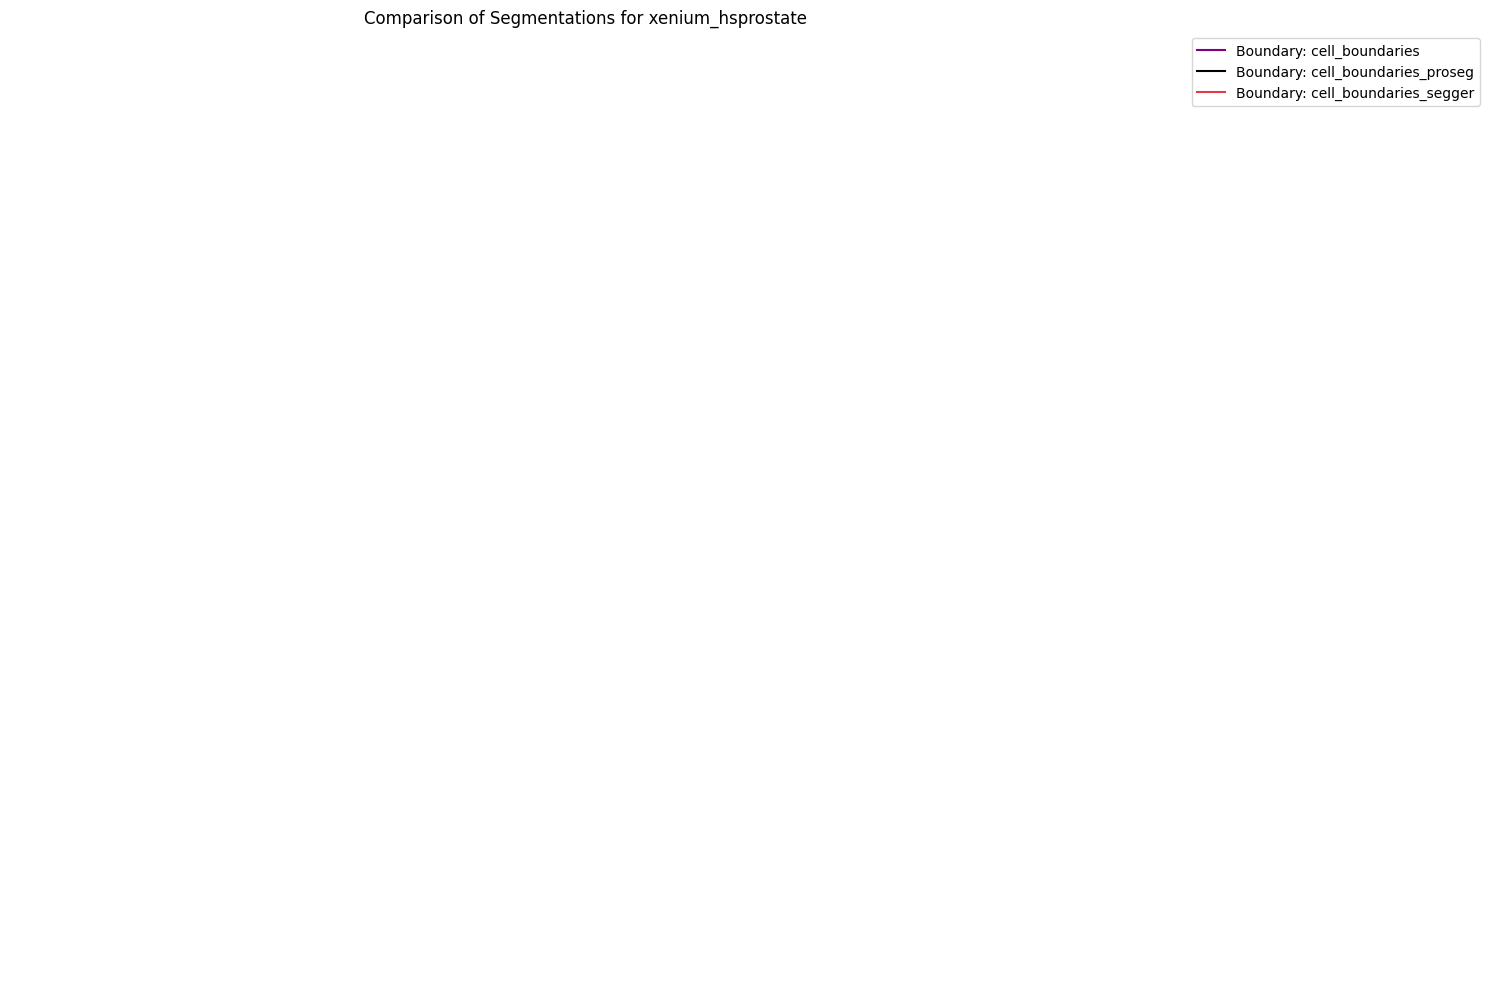

In [17]:
# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], # All three keys passed cleanly as a list
    boundary_colors=['purple', 'black', '#e63946'],
    color_key="enrichment_class",#color_key="point_source_cellular",
    use_roi=True,
    boundary_linewidth=0.6, figsize=(15,15),   # Solid, crisp outlines
    roi=(5000, 5600, 1600, 2100),scatter_size=0.3,# Your bounding box coordinates
    
    title=f"Comparison of Segmentations for {dataset_name}"
)

plt.show()



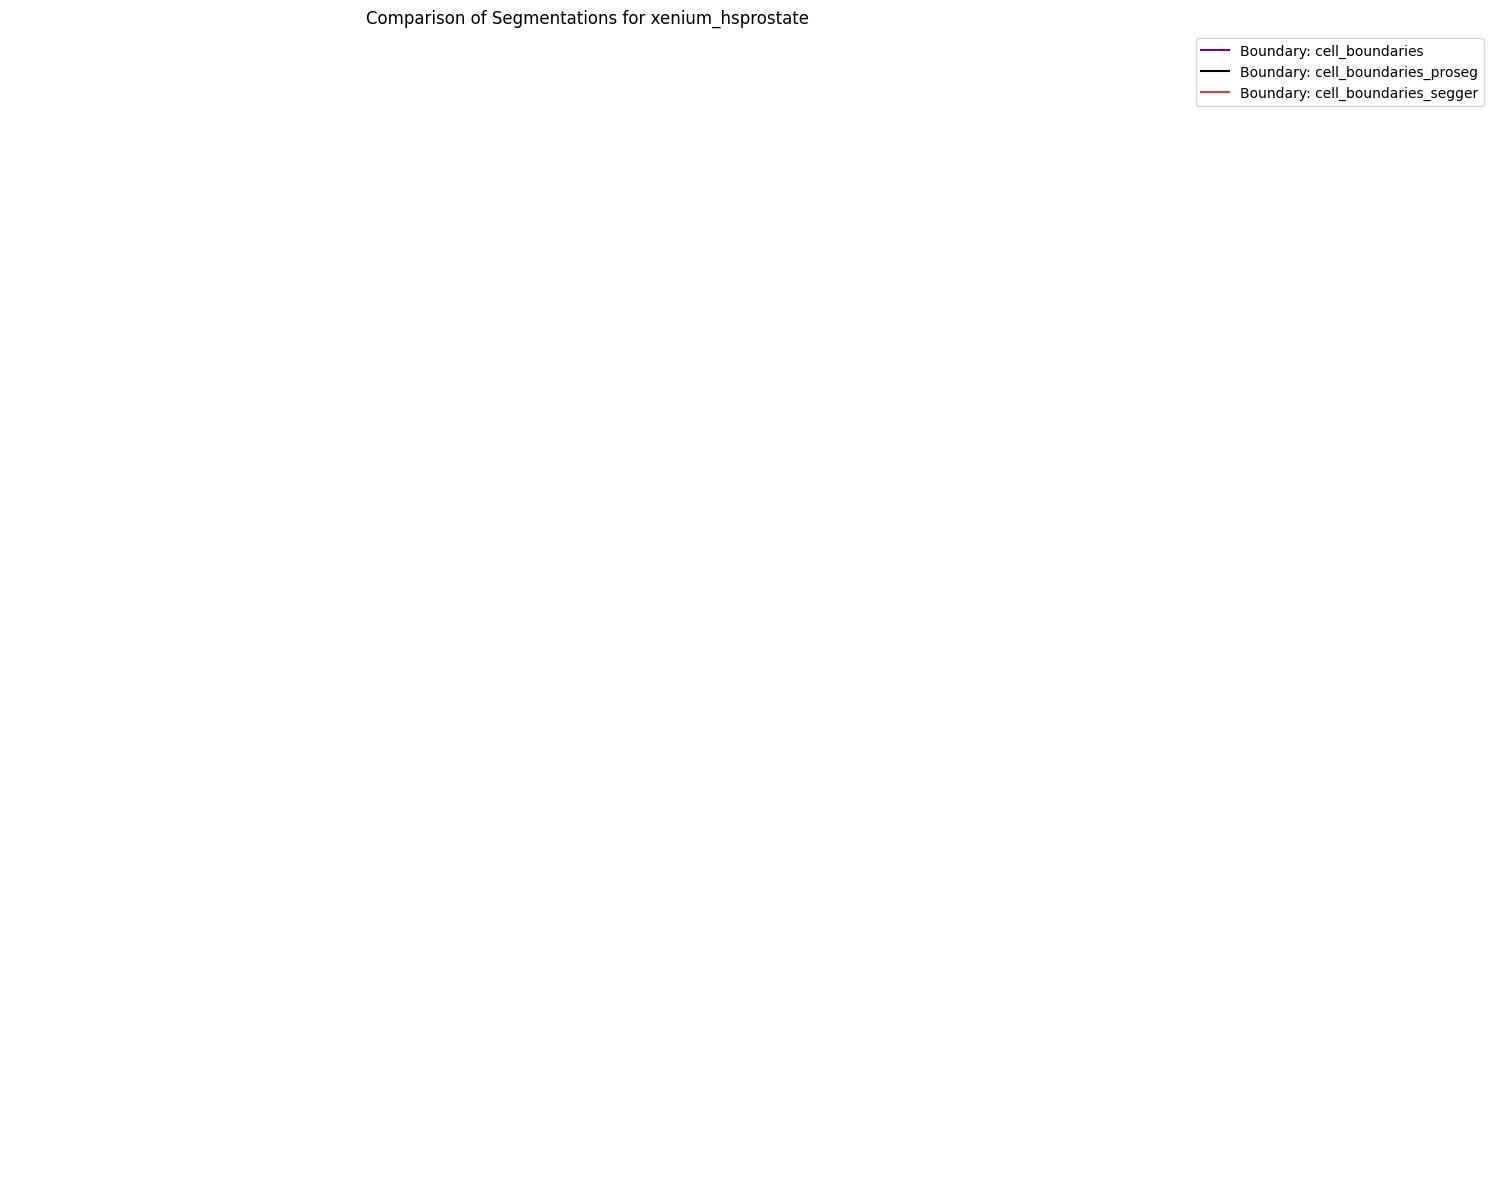

In [18]:
# 5. Plot them together!
fig, ax = spatial_transcripts(
    sdata=combined_sdata,
    shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], # All three keys passed cleanly as a list
    boundary_colors=['purple', 'black', '#e63946'],
    color_key="cosine_similarity",#color_key="point_source_cellular",
    use_roi=True,
    boundary_linewidth=3, figsize=(15,15),   # Solid, crisp outlines
    roi=(5600, 5800, 1700, 1900),scatter_size=1.0,# Your bounding box coordinates
    
    title=f"Comparison of Segmentations for {dataset_name}"
)

plt.show()

In [19]:
combined_sdata['transcripts'].columns

Index(['x', 'y', 'cell_like_type', 'is_gene', 'enrichment_class', 'cell_id',
       'fov_name', 'prob_is_urna', 'transcript_id', 'codeword_index',
       'overlaps_nucleus', 'codeword_category', 'closest_cell_type',
       'overlaps_cell', 'density_similarity_score', 'gene', 'control_probe',
       'qv', 'extracellular', 'nucleus_distance', 'cosine_similarity',
       'local_count_in_radius', 'enrichment_over_random', 'agg_type'],
      dtype='object')

In [20]:
transcripts_base_df = combined_sdata["transcripts"].compute()


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def visualize_composite_staining_intensity_alpha(
    sdata,
    trans_df,  # Base transcripts dataframe for range calculation
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    figsize: tuple[float, float] = (10, 10),
    include_channels: list[int] | None = None,  # NEW: Explicit list of channel indices to plot
    cmaps: list[str] | None = None,            # List of continuous colormaps matching selected channels
    title: str = "Composite Staining (Intensity-Based Alpha)",
    saving_path: Path | str | None = None,
    max_pct:float=98
):
    """
    Creates an aligned composite visualization of chosen staining channels.
    Pixels map their signal intensity directly to their transparency channel.
    Automatically excludes the final dummy channel.
    """
    print("\n=== [1/5] Transcript Global Ranges (Baseline calculation) ===")
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== [2/5] Raw Image Metadata (Scale0) ===")
    node = sdata.images[image_key][scale_key]
    img_dask_array = node.image.data if hasattr(node, "image") else node.data
    img_shape = img_dask_array.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== [3/5] Scaling Factor Derivation ===")
    scale_x, scale_y = img_w / t_dx, img_h / t_dy
    scale_factor = (scale_x + scale_y) / 2

    if roi is not None:
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        shifted_xmin, shifted_xmax = roi_xmin - t_xmin, roi_xmax - t_xmin
        shifted_ymin, shifted_ymax = roi_ymin - t_ymin, roi_ymax - t_ymin
        
        pixel_xmin = max(0, int(np.floor(shifted_xmin * scale_factor)))
        pixel_xmax = min(img_w, int(np.ceil(shifted_xmax * scale_factor)))
        pixel_ymin = max(0, int(np.floor(shifted_ymin * scale_factor)))
        pixel_ymax = min(img_h, int(np.ceil(shifted_ymax * scale_factor)))
        
        cropped_img_dask = img_dask_array[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img_dask = img_dask_array
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    print("\n=== [4/5] Composite Processing (Filtering Selected Indices) ===")
    if "c" in node.coords:
        full_channel_names = [str(ch) for ch in node.coords["c"].values]
    else:
        full_channel_names = [f"Channel_{i}" for i in range(img_c)]
    
    # Baseline non-dummy channels list
    valid_channel_names = full_channel_names[:-1]
    
    # Compute the cropped pixel subset into RAM safely
    cropped_pixel_matrix = cropped_img_dask.compute()
    valid_pixel_data = cropped_pixel_matrix[:-1, :, :]
    
    # If no target subset is passed, default to all non-dummy indices
    if include_channels is None:
        include_channels = list(range(len(valid_channel_names)))
        
    final_channels_to_plot = []
    final_pixel_data_list = []
    
    for idx in include_channels:
        if idx >= len(valid_channel_names) or idx < 0:
            print(f"-> [WARNING] Requested index {idx} out of range or maps to dummy channel. Skipping.")
            continue
        final_channels_to_plot.append(valid_channel_names[idx])
        final_pixel_data_list.append(valid_pixel_data[idx, :, :])
        
    print(f"-> Actively plotting selected channels: {final_channels_to_plot} (Indices: {include_channels})")
    
    # Ensure fallback colormaps list aligns with the length of chosen channels
    if cmaps is None:
        standard_palette = ['Blues', 'Greens', 'Oranges', 'Reds', 'Purples', 'YlOrBr']
        cmaps = standard_palette[:len(final_channels_to_plot)]
        if len(cmaps) < len(final_channels_to_plot):
            cmaps += ['viridis'] * (len(final_channels_to_plot) - len(cmaps))

    if len(cmaps) < len(final_channels_to_plot):
        raise ValueError(f"Length of provided colormaps list ({len(cmaps)}) does not match selected channels ({len(final_channels_to_plot)})")

    # 5. Render and Export Figure using structural RGBA blending
    print("\n=== [5/5] Plotting Intensity-Alpha Blended Figure ===")
    fig, ax = plt.subplots(figsize=figsize)
    extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
    handles = [] 
    
    for idx, ch_name in enumerate(final_channels_to_plot):
        single_channel_data = final_pixel_data_list[idx]
        
        # Normalize intensities using robust percentiles to clean background noise
        v_min, v_max = np.percentile(single_channel_data, (1, max_pct))
        if v_max == v_min: v_max += 1e-5
        normalized_data = (single_channel_data - v_min) / (v_max - v_min)
        normalized_data = np.clip(normalized_data, 0, 1)
        
        # Convert the 2D intensity profile into a mapped 3D RGB grid based on colormap
        cmap_lookup = plt.get_cmap(cmaps[idx])
        rgba_image = cmap_lookup(normalized_data)  # (Y, X, 4)
        
        # Overwrite alpha layer directly with the normalized signal intensity
        rgba_image[..., 3] = normalized_data 
        
        # Render the pre-compiled RGBA layer
        ax.imshow(
            rgba_image, 
            origin="lower", 
            extent=extent
        )
        
        # Setup legend tags using the color high-point
        marker_color = cmap_lookup(0.8)
        handles.append(plt.Line2D([0], [0], color=marker_color, lw=4, label=ch_name))

    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.axis("off")
    ax.legend(handles=handles, title="Stainings", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    
    if saving_path is not None:
        save_dir = Path(saving_path)
        save_dir.mkdir(parents=True, exist_ok=True)
        roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}" if roi is not None else ""
        ch_suffix = f"_channels_" + "_".join(map(str, include_channels))
        pdf_filename = f"staining_composite{ch_suffix}_intensity_alpha{roi_suffix}.pdf"
        
        fig.savefig(save_dir / pdf_filename, bbox_inches="tight", dpi=300)
        print(f"-> Intensity-alpha composite PDF saved: {pdf_filename}")
        
    plt.show()
    plt.close(fig)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===


-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_840_1020.pdf


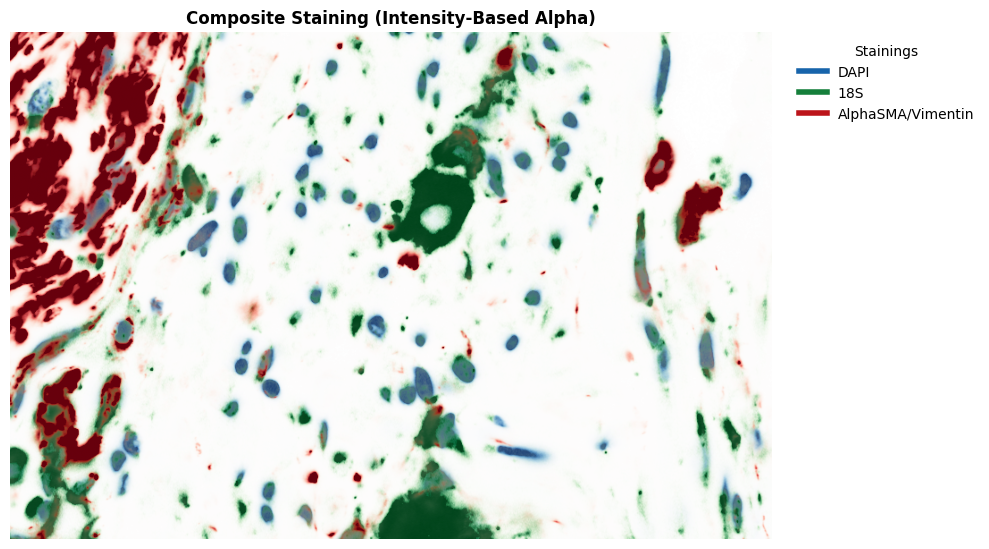

In [22]:
visualize_composite_staining_intensity_alpha(
    sdata=combined_sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(840, 1020, 2680, 2800),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=95.0
)

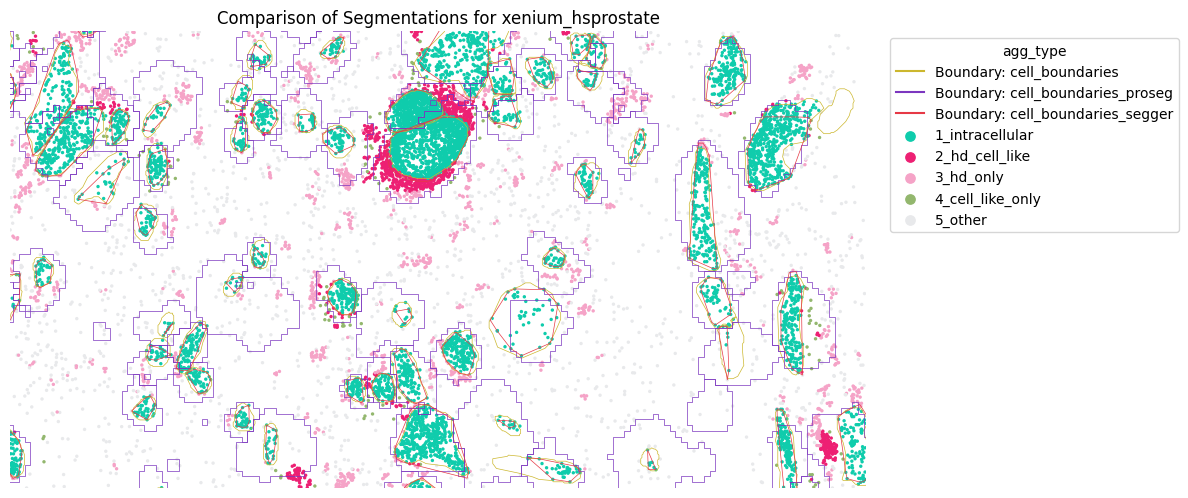

In [23]:
import os
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define your ROI and color key variables cleanly
roi_coords = roi=(850, 1000, 2700, 2780)
chosen_color_key = "agg_type"
my_category_colors = ["#0FCCAC", "#ED2073", "#f5a3c7", "#93b76e", "#e8e9eb"]

# 5. Plot them together!
fig, ax = spatial_transcripts(sdata=combined_sdata,shapes_key=["cell_boundaries", "cell_boundaries_proseg", "cell_boundaries_segger"], 
    color_key=chosen_color_key,use_roi=True, 
    boundary_colors=['#ccb72e', '#7c36bf', '#e63946'],boundary_linewidth=0.5, 
    figsize=(12, 12),   
    roi=roi_coords,
    scatter_size=4.0, colormap=my_category_colors,  
    rasterize=True,                                           # <-- Enforces pixel rasterization for the scatter layer
    title=f"Comparison of Segmentations for {dataset_name}"
)

# Convert ROI tuple into a clean string layout for the filename
roi_str = "_".join(map(str, roi_coords))

# Generate a clean, descriptive filename
output_filename = f"spatial_transcripts_{dataset_name}_{chosen_color_key}_roi_{roi_str}.pdf"

# Save the figure with a tight bounding box
fig.savefig(
    os.path.join(saving_path, output_filename),
    format='pdf',
    bbox_inches='tight',
    dpi=300                                                   # Sets resolution for the rasterized transcript points
)

plt.show()


Plotting normalized maps for rois...


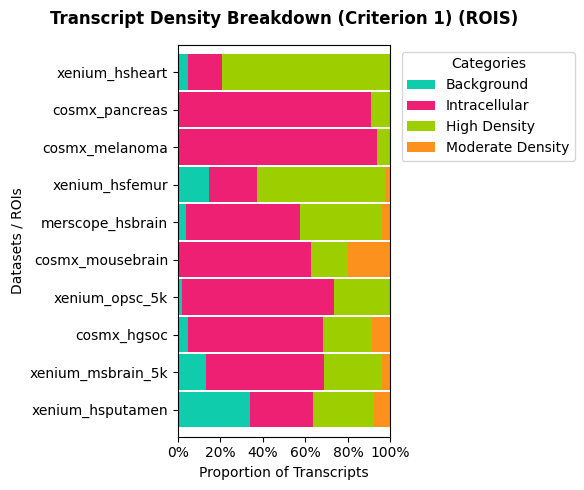

Saved normalized plot to: ./plots_output/rois_Crit1_Density_proportions.pdf


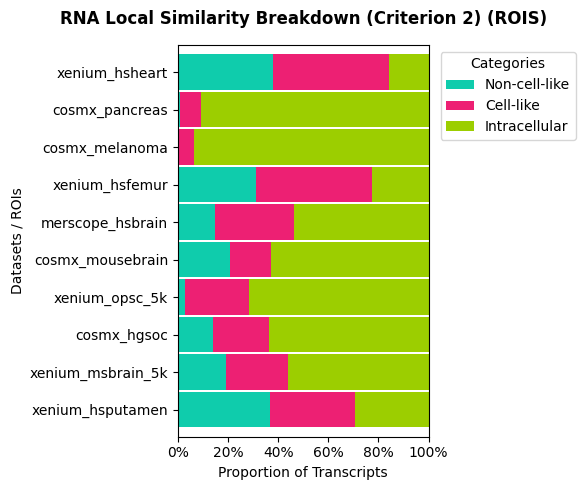

Saved normalized plot to: ./plots_output/rois_Crit2_Similarity_proportions.pdf


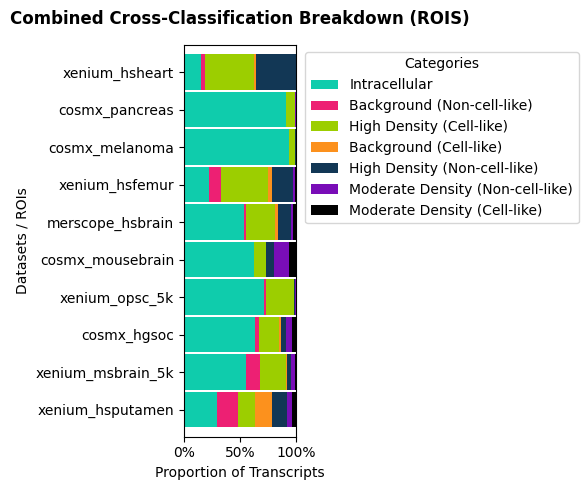

Saved normalized plot to: ./plots_output/rois_Combined_Criteria_proportions.pdf

Plotting normalized maps for rois_proseg...


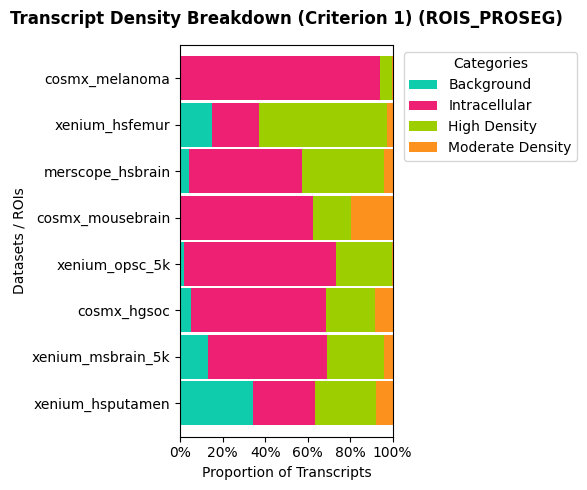

Saved normalized plot to: ./plots_output/rois_proseg_Crit1_Density_proportions.pdf


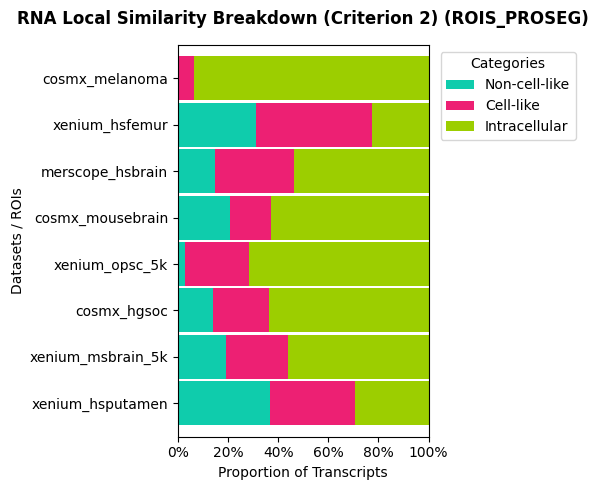

Saved normalized plot to: ./plots_output/rois_proseg_Crit2_Similarity_proportions.pdf


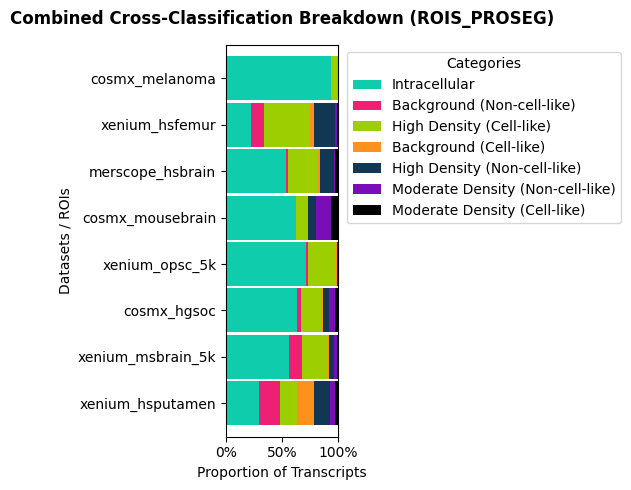

Saved normalized plot to: ./plots_output/rois_proseg_Combined_Criteria_proportions.pdf


In [24]:
# To get values between 0.0 and 1.0:
pd.crosstab(transcripts['overlaps_cell'], transcripts['extracellular'], normalize='all')

NameError: name 'transcripts' is not defined

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your data is already computed:
# transcripts = sdata['transcripts'].compute()

# Target column identifying your individual samples (e.g., 'sample_id', 'library_id')
# Replace 'sample_id' with your actual column name
sample_col = 'sample_id' 

# --- CRITERION 1: Intracellular vs Enrichment Class ---
transcripts['Crit1_Enrichment'] = np.where(
    transcripts['overlaps_cell'] == True, 
    'Intracellular', 
    transcripts['enrichment_class']
)

# --- CRITERION 2: Intracellular vs Cell-Like Morphology ---
transcripts['Crit2_Morphology'] = np.select(
    condlist=[
        transcripts['overlaps_cell'] == True,
        (transcripts['overlaps_cell'] == False) & (transcripts['extracellular'] == True),
        (transcripts['overlaps_cell'] == False) & (transcripts['extracellular'] != True)
    ],
    choicelist=[
        'Intracellular',
        'Non-cell-like',
        'Cell-like',
    ],
    default='Unclassified'
)

# --- BOTH COMBINED: Cross-classification of uRNA ---
transcripts['Combined_Criteria'] = np.where(
    transcripts['overlaps_cell'] == True,
    'Intracellular',
    transcripts['Crit1_Enrichment'].astype(str) + " (" + transcripts['Crit2_Morphology'].astype(str) + ")"
)

# 1. Count Criterion 1 (Enrichment)
crit1_counts = transcripts['Crit1_Enrichment'].value_counts()

# 2. Count Criterion 2 (Morphology)
crit2_counts = transcripts['Crit2_Morphology'].value_counts()

# 3. Count Both Simultaneously (Combined uRNA details)
combined_counts = transcripts['Combined_Criteria'].value_counts()

# --- Print the exact headcounts directly ---
print("--- CRITERION 1 COUNTS ---")
print(crit1_counts)

print("\n--- CRITERION 2 COUNTS ---")
print(crit2_counts)

print("\n--- COMBINED COUNTS ---")
print(combined_counts)

def plot_single_sample_stack(counts_series, title, cmap='Set2'):
    """
    Plots a single absolute stacked bar for one sample.
    """
    # Convert the single series into a 1-row DataFrame for plotting
    df_single = pd.DataFrame(counts_series).T
    
    fig, ax = plt.subplots(figsize=(4, 6)) # Narrower plot since it's just one bar
    
    # Plot the single stacked bar
    df_single.plot(kind='bar', stacked=True, ax=ax, cmap=cmap, edgecolor='black', linewidth=0.5)
    
    # Clean up the formatting
    ax.set_title(title, fontsize=12, weight='bold', pad=15)
    ax.set_ylabel('Number of Transcripts (Raw Counts)', fontsize=11)
    ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
    
    # Hide the X-axis label/ticks since there's only 1 sample
    ax.set_xticks([])
    ax.set_xlabel('Your Sample')
    
    # Position the legend cleanly
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Categories")
    plt.tight_layout()
    
    plt.show()
    plt.close(fig)

# --- Generate your single-bar plots ---
plot_single_sample_stack(crit1_counts, "Criterion 1 Breakdown", cmap="Set2")
plot_single_sample_stack(crit2_counts, "Criterion 2 Breakdown", cmap="Pastel1")
plot_single_sample_stack(combined_counts, "Combined Cross-Classification", cmap="tab10")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter for only non-intracellular transcripts (uRNA)
urna = transcripts[transcripts['overlaps_cell'] == False].copy()

# 2. Map Criterion 2 explicitly to its descriptive labels
urna['Morphology_Class'] = np.where(urna['extracellular'] == True, 'Non-cell-like','Cell-like')

# Create cross-tabulation normalized by the GRAND TOTAL
confusion_matrix_total_pct = pd.crosstab(
    index=urna['enrichment_class'], 
    columns=urna['Morphology_Class'],
    normalize='all'  # <--- Calculates percentage of the global total
)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    confusion_matrix_total_pct, 
    annot=True,          
    fmt=".1%",           
    cmap="YlGnBu",       
    linewidths=0.5,      
    cbar_kws={'label': 'Percentage of Total uRNA'}
)

ax.set_title('uRNA Breakdown (Total Percentages)\n(Percentage of overall uRNA population)', fontsize=11, weight='bold', pad=15)
ax.set_ylabel('Enrichment Class (Criterion 1)', fontsize=11)
ax.set_xlabel('Morphology Class (Criterion 2)', fontsize=11)

plt.tight_layout()
plt.show()
plt.close(fig)

NameError: name 'transcripts' is not defined

--- CRITERION 1 COUNTS ---
Crit1_Enrichment
Intracellular       11921036
High Density         2989428
Moderate Density     2210328
Background           1892877
Name: count, dtype: int64

--- CRITERION 2 COUNTS ---
Crit2_Morphology
Intracellular    11921036
Non-cell-like     5230304
Cell-like         1862329
Name: count, dtype: int64

--- COMBINED COUNTS ---
Combined_Criteria
Intracellular                       11921036
Moderate Density (Non-cell-like)     1862081
Background (Non-cell-like)           1725820
High Density (Non-cell-like)         1642403
High Density (Cell-like)             1347025
Moderate Density (Cell-like)          348247
Background (Cell-like)                167057
Name: count, dtype: int64


# Other stuff